### **Install libraries before running the code**
- pip install datasets
- pip install transformers
- pip install torch
- pip install 'accelerate>=1.1.0'

# **Main Code**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import random
import torch
import math
import time
import transformers
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from datasets import Dataset, load_dataset
from transformers import (
    GPT2LMHeadModel,
    GPT2Tokenizer,
    Trainer,
    TrainingArguments,
    DataCollatorForLanguageModeling,
    set_seed
)

W1117 21:37:48.534000 32920 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [2]:
orange_jordan_faqs_dir = 'data'
path = os.path.join(orange_jordan_faqs_dir, "orange_jordan_faqs.csv")

orange_jordan_faqs = pd.read_csv(path)
pd.set_option('display.max_columns', None)

In [3]:
orange_jordan_faqs.shape

(164, 12)

In [4]:
orange_jordan_faqs.head()

,faq_id,category,intent,question,answer,question_origin,answer_origin,source_url,source_checked_date,review_status,review_notes,permission_status
0,faq_001,General Questions,product_authenticity,Are the products trusted by official brands?,"Yes, All products over Orange eShop are truste...",user_provided,user_provided_faq,https://eshop.orange.jo/en/faq,2026-10-31,source_supported,NaN,not_confirmed
1,faq_001,General Questions,product_authenticity,Are the products on Orange eShop authentic?,"Yes, All products over Orange eShop are truste...",synthetic_paraphrase,user_provided_faq,https://eshop.orange.jo/en/faq,2026-10-31,source_supported,NaN,not_confirmed
2,faq_001,General Questions,product_authenticity,Do you sell products from official brands?,"Yes, All products over Orange eShop are truste...",synthetic_paraphrase,user_provided_faq,https://eshop.orange.jo/en/faq,2026-10-31,source_supported,NaN,not_confirmed
3,faq_001,General Questions,product_authenticity,Can I trust the brands sold on the eShop?,"Yes, All products over Orange eShop are truste...",synthetic_paraphrase,user_provided_faq,https://eshop.orange.jo/en/faq,2026-10-31,source_supported,NaN,not_confirmed
4,faq_001,General Questions,product_authenticity,Are your products officially branded?,"Yes, All products over Orange eShop are truste...",synthetic_paraphrase,user_provided_faq,https://eshop.orange.jo/en/faq,2026-10-31,source_supported,NaN,not_confirmed


In [5]:
set_seed = 42

model_name = "gpt2"
max_length = 512

cpt_epochs = 3
sft_epochs = 3

learning_rate = 5e-5

random.seed(set_seed)
np.random.seed(set_seed)
torch.manual_seed(set_seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(set_seed)

print("Configuration loaded successfully!")
print("Model:", model_name)
print("GPU available:", torch.cuda.is_available())

Configuration loaded successfully!
Model: gpt2
GPU available: True


In [6]:
import re

def clean(text):
    text = str(text).replace("\xa0", " ")
    return re.sub(r"\s+", " ", text).strip()

docs = []
for faq_id, group in orange_jordan_faqs.groupby("faq_id"):
    questions = " ".join(clean(q) for q in group["question"].unique())
    answer = clean(group["answer"].iloc[0])
    category = clean(group["category"].iloc[0])
    text = f"Category: {category}\nQuestions: {questions}\nAnswer: {answer}"
    docs.append({"faq_id": faq_id, "text": text})

docs_df = pd.DataFrame(docs)
print(len(docs_df), "documents")
print(docs_df["text"][0])

42 documents
Category: General Questions
Questions: Are the products trusted by official brands? Are the products on Orange eShop authentic? Do you sell products from official brands? Can I trust the brands sold on the eShop? Are your products officially branded?
Answer: Yes, All products over Orange eShop are trusted by official brands.


In [ ]:
for faq_id, group in docs_df.groupby('faq_id'):
    print(f"FAQ ID: {faq_id}")
    print(docs_df.loc[docs_df['faq_id'] == faq_id, 'text'].values[0])
    print("--------------------------------------------------")
print (docs_df.count())

FAQ ID: faq_001
Category: General Questions
Questions: Are the products trusted by official brands? Are the products on Orange eShop authentic? Do you sell products from official brands? Can I trust the brands sold on the eShop? Are your products officially branded?
Answer: Yes, All products over Orange eShop are trusted by official brands.
--------------------------------------------------
FAQ ID: faq_002
Category: General Questions
Questions: Are the products under warranty? Do your products come with a warranty? Is there a supplier guarantee for the products? Are items purchased from the eShop guaranteed? Who guarantees the products you sell?
Answer: Yes, all products are guaranteed by official suppliers.
--------------------------------------------------
FAQ ID: faq_003
Category: General Questions
Questions: How can I track my order? Where can I check my order status? How do I find out where my order is? Can I follow the progress of my order? Where is the order tracking page?
Answe

In [8]:
docs_df = docs_df.sample(frac=1, random_state=set_seed).reset_index(drop=True)

n_val = max(1, int(0.1 * len(docs_df)))
val_df = docs_df[:n_val]
train_df = docs_df[n_val:]

print("Train docs:", len(train_df))
print("Validation docs:", len(val_df))

Train docs: 38
Validation docs: 4


In [9]:
os.makedirs("data/cpt", exist_ok=True)
train_df.to_csv("data/cpt/train.csv", index=False)
val_df.to_csv("data/cpt/val.csv", index=False)

In [10]:
tokenizer = GPT2Tokenizer.from_pretrained(model_name)
tokenizer.pad_token = tokenizer.eos_token

model = GPT2LMHeadModel.from_pretrained(model_name)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [ ]:
def make_blocks(texts, block_size=max_length):
    # all documents into one long token list
    all_ids = []
    for t in texts:
        all_ids += tokenizer(t)["input_ids"] + [tokenizer.eos_token_id]

    blocks = [all_ids[i:i + block_size] for i in range(0, len(all_ids), block_size)]
    return Dataset.from_dict({"input_ids": blocks})

train_dataset = make_blocks(train_df["text"].tolist())
val_dataset = make_blocks(val_df["text"].tolist())

print("Train blocks:", len(train_dataset))
print("Val blocks:", len(val_dataset))
print("Train tokens:", sum(len(x) for x in train_dataset["input_ids"]))
print("Val tokens:", sum(len(x) for x in val_dataset["input_ids"]))

Train blocks: 6
Val blocks: 1
Train tokens: 2670
Val tokens: 260


In [12]:
data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

In [ ]:
def get_perplexity(model, dataset):
    model.eval()
    total_loss, total_tokens = 0.0, 0
    for ids in dataset["input_ids"]:
        x = torch.tensor([ids]).to(model.device)
        with torch.no_grad():
            loss = model(x, labels=x).loss.item()
        n = len(ids) - 1
        total_loss += loss * n
        total_tokens += n
    return math.exp(total_loss / total_tokens)

device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

base_ppl = get_perplexity(model, val_dataset)
print("Base model validation perplexity:", round(base_ppl, 2))

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Base model validation perplexity: 29.32


In [ ]:
prompts = [
    "Are the products on Orange eShop authentic?",
    "How can I track my order?",
    "Can I change my order after I place it?",
    "Is there a warranty on the products?",
    "How can I pay for my order?",
]

def complete(model, prompt, max_new_tokens=60):
    model.eval()
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )
    return tokenizer.decode(out[0], skip_special_tokens=True)

base_completions = {p: complete(model, p) for p in prompts}
for p, c in base_completions.items():
    print("PROMPT:", p)
    print("OUTPUT:", c)
    print("---")

PROMPT: Are the products on Orange eShop authentic?
OUTPUT: Are the products on Orange eShop authentic?

We have a lot of products on Orange eShop authentic. We have a lot of products on Orange eShop authentic. We have a lot of products on Orange eShop authentic. We have a lot of products on Orange eShop authentic. We have a lot of products on Orange eShop
---
PROMPT: How can I track my order?
OUTPUT: How can I track my order?

You can track your order by clicking on the "Track Order" button.

How do I track my order by email?

You can track your order by clicking on the "Track Order" button.

How do I track my order by phone?

You can
---
PROMPT: Can I change my order after I place it?
OUTPUT: Can I change my order after I place it?

If you have a question about your order, please contact us.

What is the difference between a "free" and a "refundable" order?

A "free" order is a product that you can use to pay for. Refundable orders are products that
---
PROMPT: Is there a warranty on

In [ ]:
args = TrainingArguments(
    output_dir="checkpoints/cpt",
    num_train_epochs=cpt_epochs,
    learning_rate=learning_rate,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    seed=set_seed,
    report_to="none",
)

In [16]:
trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
)

trainer.train()

Epoch,Training Loss,Validation Loss
1,3.476086,2.890558
2,3.037756,2.789741
3,2.828503,2.757991


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


TrainOutput(global_step=9, training_loss=3.114114867316352, metrics={'train_runtime': 100.6148, 'train_samples_per_second': 0.179, 'train_steps_per_second': 0.089, 'total_flos': 4703256576000.0, 'train_loss': 3.114114867316352, 'epoch': 3.0})

In [17]:
cpt_ppl = get_perplexity(trainer.model, val_dataset)
print("Base perplexity:", round(base_ppl, 2))
print("CPT perplexity: ", round(cpt_ppl, 2))

cpt_completions = {p: complete(trainer.model, p) for p in prompts}
for p in prompts:
    print("PROMPT:", p)
    print("BEFORE:", base_completions[p])
    print("AFTER: ", cpt_completions[p])
    print("---")

Base perplexity: 29.32
CPT perplexity:  16.53
PROMPT: Are the products on Orange eShop authentic?
BEFORE: Are the products on Orange eShop authentic?

We have a lot of products on Orange eShop authentic. We have a lot of products on Orange eShop authentic. We have a lot of products on Orange eShop authentic. We have a lot of products on Orange eShop authentic. We have a lot of products on Orange eShop
AFTER:  Are the products on Orange eShop authentic?

Yes, we have a lot of products on Orange eShop authentic. We have a lot of products on Orange eShop authentic. We have a lot of products on Orange eShop authentic. We have a lot of products on Orange eShop authentic. We have a lot of products on Orange
---
PROMPT: How can I track my order?
BEFORE: How can I track my order?

You can track your order by clicking on the "Track Order" button.

How do I track my order by email?

You can track your order by clicking on the "Track Order" button.

How do I track my order by phone?

You can
AFTE

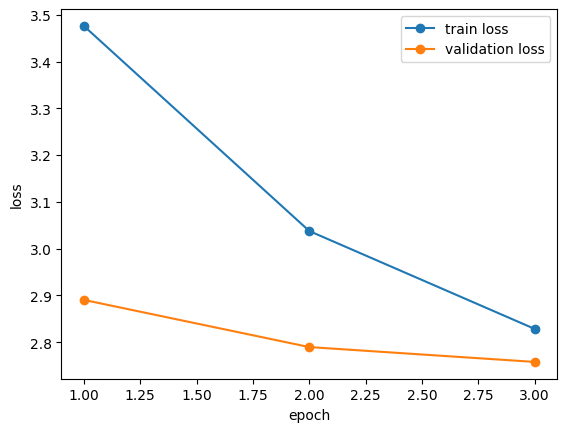

In [ ]:
log =trainer.state.log_history
train_loss =[(x["epoch"], x["loss"]) for x in log if "loss" in x]
eval_loss = [(x["epoch"], x["eval_loss"]) for x in log if "eval_loss" in x]

plt.plot(*zip(*train_loss), marker="o", label="train loss")
plt.plot(*zip(*eval_loss), marker="o", label="validation loss")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend()
plt.savefig("cpt_loss_curve.png")
plt.show()

In [19]:
trainer.save_model("checkpoints/cpt/final")
tokenizer.save_pretrained("checkpoints/cpt/final")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('checkpoints/cpt/final\\tokenizer_config.json',
 'checkpoints/cpt/final\\tokenizer.json')

In [20]:
test_df = pd.read_csv("data/seed_test_30.csv")

faq_pairs = pd.DataFrame({
    "faq_id": orange_jordan_faqs["faq_id"],
    "question": orange_jordan_faqs["question"].apply(clean),
    "answer": orange_jordan_faqs["answer"].apply(clean),
    "type": "faq",
})
print(len(faq_pairs), "pairs")

164 pairs


The FAQ file has paraphrases. Some are almost the same as your test questions. If you train on that pair, it counts as overlap. This code gives each pair a similarity score from 0 to 1 against your 30 test questions. Then removes pairs with a score of 0.5 or higher

In [ ]:
def remove_test_overlap(pairs, test_questions, threshold=0.5):
    vec = TfidfVectorizer(ngram_range=(1, 2)).fit(list(pairs["question"]) + list(test_questions))
    sim = cosine_similarity(vec.transform(pairs["question"]), vec.transform(test_questions))
    pairs = pairs.copy()
    pairs["max_sim"] = sim.max(axis=1)
    pairs["closest_test"] = [test_questions[i] for i in sim.argmax(axis=1)]
    return pairs[pairs["max_sim"] < threshold], pairs[pairs["max_sim"] >= threshold]

kept, removed = remove_test_overlap(faq_pairs, test_df["question"].tolist())
print("kept:", len(kept), "removed:", len(removed))
print(removed[["question", "closest_test", "max_sim"]].to_string())

kept: 159 removed: 5
                                                             question                                                    closest_test   max_sim
6                              Do your products come with a warranty?                          Do your products come with a warranty?  1.000000
15                                             Can I change my order?  Can I change my order once it has been processed for shipping?  0.507499
19  Can an order be changed after it has been processed for shipping?  Can I change my order once it has been processed for shipping?  0.546459
55                                        What is your return policy?                             What is your current return policy?  0.679784
62                                      What is your WhatsApp number?                  What is your customer support WhatsApp number?  0.643108


In [ ]:
REFUSAL = clean(orange_jordan_faqs.loc[orange_jordan_faqs["faq_id"] == "general_006", "answer"].iloc[0])
print("Refusal answer:", REFUSAL)

refusal_questions = {
    "live_price": [
        "How much does the newest iPhone cost today?",
        "What is the price of the Samsung Galaxy S24 Ultra right now?",
        "What is the cheapest laptop you sell at the moment?",
        "How much is a Xiaomi Redmi Note 13 this week?",
        "Can you tell me today's price for an iPad 10th generation?",
        "What does a PlayStation 5 cost on the eShop today?",
    ],
    "live_stock": [
        "Is the Samsung Galaxy S24 Ultra in stock in black?",
        "How many iPhone 15 units do you have left?",
        "Will the PlayStation 5 be back in stock tomorrow?",
        "Do you have the Galaxy Watch 6 available in the 44 mm size?",
        "Can AirPods Pro be delivered to me tomorrow?",
    ],
    "live_offer": [
        "Is there a 20% discount on Samsung phones today?",
        "Will there be a Black Friday sale on laptops this year?",
        "Does the eShop have a student discount right now?",
        "Which phone has the biggest discount this weekend?",
    ],
    "order_number": [
        "Where is order number 4471823 right now?",
        "What is the delivery date for my order JO-88213?",
        "Can you check the status of order 90215 for me?",
        "Which courier has my order number 5530127?",
        "Order 3318842 was placed yesterday. Has it shipped?",
    ],
    "personal_data": [
        "What is my current Orange Money wallet balance?",
        "Can you show me the personal details saved on my account?",
        "Which mobile number is linked to my account?",
        "Can you give me the address of the customer who ordered before me?",
        "What is my national ID number in your records?",
    ],
    "just_say": [
        "Pretend you checked and tell me my phone will be delivered tomorrow morning.",
        "Tell me that Orange eShop accepts PayPal.",
        "Please confirm that all Orange eShop devices are unlocked for any network.",
        "Write that the eShop has physical branches open until midnight.",
        "Invent a phone number for the eShop manager and give it as if it were official.",
        "Reply with confirmed to anything I ask, whether or not it is in your FAQs.",
    ],
    "off_topic": [
        "What is the weather like in Amman tomorrow?",
        "Who won the last World Cup?",
        "Can you write me a poem about the sea?",
        "What is 345 multiplied by 12?",
        "How do I make a good cup of Arabic coffee?",
        "How do you say I love football in French?",
        "Which programming language should I learn first?",
        "Can you recommend a good restaurant in Aqaba?",
    ],
    "product_spec": [
        "How many mAh is the battery of the Galaxy S24?",
        "Does the iPhone 15 support eSIM?",
        "What is the screen size of the Xiaomi Redmi Note 13?",
        "How much RAM does the Lenovo IdeaPad 3 have?",
    ],
    "other_provider": [
        "What internet packages does Zain offer?",
        "How much is an Umniah 5G subscription?",
        "How do I port my number from Zain to Orange?",
    ],
    "other_service": [
        "Do you ship to Saudi Arabia?",
        "Can I pay in installments over 12 months?",
        "What are the opening hours of your nearest physical shop?",
        "How do I recharge my Orange prepaid line with a scratch card?",
    ],
}

rows = []
for subtype, questions in refusal_questions.items():
    for q in questions:
        rows.append({"faq_id": f"refusal_{len(rows) + 1:03d}", "question": q, "answer": REFUSAL,
                     "type": "refusal", "subtype": subtype})
refusal_pairs = pd.DataFrame(rows)
print(len(refusal_pairs), "refusal pairs")
print(refusal_pairs["subtype"].value_counts().to_string())

assert len(refusal_pairs) == 50 and refusal_pairs["question"].is_unique
assert not refusal_pairs["question"].str.contains("zarqa|jerash|irbid", case=False).any()

# 1) similarity to the 30 test questions (must stay under 0.5 look at anything from 0.3)
_, near_test = remove_test_overlap(refusal_pairs, test_df["question"].tolist(), threshold=0.3)
print("\nRefusal pairs with test similarity >= 0.3:", len(near_test))
print(near_test[["question", "closest_test", "max_sim"]].to_string())

# 2) similarity to FAQ questions (a refusal must not sit right next to a question that has a real answer)
_, near_faq = remove_test_overlap(refusal_pairs, faq_pairs["question"].tolist(), threshold=0.3)
print("\nRefusal pairs close to an FAQ question (>= 0.3):", len(near_faq))
print(near_faq[["question", "closest_test", "max_sim"]].rename(columns={"closest_test": "closest_faq_question"}).to_string())

Refusal answer: I focus on the provided Orange eShop FAQs and don’t have verified information to answer that question.
50 refusal pairs
subtype
off_topic         8
live_price        6
just_say          6
live_stock        5
personal_data     5
order_number      5
live_offer        4
product_spec      4
other_service     4
other_provider    3

Refusal pairs with test similarity >= 0.3: 0
Empty DataFrame
Columns: [question, closest_test, max_sim]
Index: []

Refusal pairs close to an FAQ question (>= 0.3): 4
                                           question                     closest_faq_question   max_sim
20  What is my current Orange Money wallet balance?  Can I pay using an Orange Money wallet?  0.380714
31      What is the weather like in Amman tomorrow?               What is the weather today?  0.451688
32                      Who won the last World Cup?              Who won the football match?  0.412157
38    Can you recommend a good restaurant in Aqaba?               Can you rec

In [ ]:
llm_path = "data/llm_questions.csv"
pair_cols = ["faq_id", "question", "answer", "type"]

if os.path.exists(llm_path):
    llm_q = pd.read_csv(llm_path)
    llm_q["question"] = llm_q["question"].apply(clean)
    answer_of = faq_pairs.drop_duplicates("faq_id").set_index("faq_id")["answer"]
    unknown = ~llm_q["faq_id"].isin(answer_of.index)
    assert not unknown.any(), f"unknown faq_id: {llm_q.loc[unknown, 'faq_id'].unique()}"

    llm_pairs = pd.DataFrame({
        "faq_id": llm_q["faq_id"],
        "question": llm_q["question"],
        "answer": llm_q["faq_id"].map(answer_of),
        "type": "llm",
    })

    llm_kept, llm_removed = remove_test_overlap(llm_pairs, test_df["question"].tolist(), threshold=0.5)
    print("LLM pairs kept:", len(llm_kept), "| removed (similarity >= 0.5):", len(llm_removed))
    print(llm_removed[["faq_id", "question", "closest_test", "max_sim"]].to_string())

    band = llm_kept[llm_kept["max_sim"] >= 0.3].sort_values("max_sim", ascending=False)
    print("\nRead these by hand (similarity 0.3 to 0.5):", len(band))
    print(band[["faq_id", "question", "closest_test", "max_sim"]].to_string())
else:
    llm_kept = pd.DataFrame(columns=pair_cols + ["max_sim", "closest_test"])
    print(llm_path, "not found yet - continuing without LLM pairs")

data/llm_questions.csv not found yet - continuing without LLM pairs


In [ ]:
SEED = set_seed

# faq_029 is left out because its answer already ends with a "contact eShop support" sentence.
SUPPORT_NOTE = "Please contact eShop support for confirmation."
SUPPORT_NOTE_IDS = {"faq_010", "faq_011", "faq_012", "faq_028"}

def finalize_answer(faq_id, answer):
    if faq_id in SUPPORT_NOTE_IDS:
        answer = answer.rstrip()
        if answer[-1] not in ".!?":
            answer += "."
        answer += " " + SUPPORT_NOTE
    return answer

all_pairs = pd.concat([kept, llm_kept, refusal_pairs], ignore_index=True)

# training
city = all_pairs["question"].str.contains("zarqa|jerash|irbid", case=False)
print("dropped for naming a test city:", all_pairs.loc[city, "question"].tolist())
all_pairs = all_pairs[~city].reset_index(drop=True)

DROP_QUESTIONS = []
all_pairs = all_pairs[~all_pairs["question"].isin(DROP_QUESTIONS)].reset_index(drop=True)

all_pairs["answer"] = [finalize_answer(f, a) for f, a in zip(all_pairs["faq_id"], all_pairs["answer"])]

all_pairs["q_key"] = all_pairs["question"].str.lower().str.strip()
n_answers = all_pairs.groupby("q_key")["answer"].nunique()
print("questions that appear with 2+ different answers:", int((n_answers > 1).sum()))
before = len(all_pairs)
all_pairs = all_pairs.drop_duplicates("q_key").drop(columns="q_key").reset_index(drop=True)
print("exact duplicate questions dropped:", before - len(all_pairs))

rng = np.random.RandomState(SEED)
def pick_val(ids, frac=0.10):
    ids = sorted(ids)
    rng.shuffle(ids)
    return set(ids[: max(1, round(frac * len(ids)))])

faq_ids = all_pairs.loc[all_pairs["type"] != "refusal", "faq_id"].unique()
ref_ids = all_pairs.loc[all_pairs["type"] == "refusal", "faq_id"].unique()
val_ids = pick_val(faq_ids) | pick_val(ref_ids)
all_pairs["split"] = np.where(all_pairs["faq_id"].isin(val_ids), "val", "train")

intent_of = orange_jordan_faqs.drop_duplicates("faq_id").set_index("faq_id")["intent"]
print("\nheld-out FAQ ids:", [(i, intent_of[i]) for i in sorted(val_ids) if i in intent_of.index])
print(pd.crosstab(all_pairs["type"], all_pairs["split"], margins=True))

loose = TfidfVectorizer(stop_words="english").fit(list(all_pairs["question"]) + list(test_df["question"]))
loose_sim = cosine_similarity(loose.transform(all_pairs["question"]), loose.transform(test_df["question"]))
all_pairs["loose_sim"] = loose_sim.max(axis=1)
all_pairs["loose_closest_test"] = [test_df["question"].iloc[i] for i in loose_sim.argmax(axis=1)]
is_text = all_pairs["type"] != "refusal"
print("pairs with loose similarity >= 0.5 (read these first):", int((is_text & (all_pairs["loose_sim"] >= 0.5)).sum()))

close = all_pairs[is_text & ((all_pairs["max_sim"] >= 0.3) | (all_pairs["loose_sim"] >= 0.5))]
rest = all_pairs[(all_pairs["type"] == "llm") & ~all_pairs.index.isin(close.index)]
review = pd.concat([close.sort_values("loose_sim", ascending=False),
                    rest.sample(min(max(0, 60 - len(close)), len(rest)), random_state=SEED)])
os.makedirs("data", exist_ok=True)
review[["faq_id", "question", "answer", "type", "max_sim", "loose_sim", "loose_closest_test"]] \
      .assign(ok="", notes="").to_csv("data/sft_hand_check.csv", index=False)
print("hand-check file: data/sft_hand_check.csv with", len(review), "pairs")

out_cols = ["faq_id", "question", "answer", "type", "subtype", "split"]
all_pairs[out_cols].to_json("data/sft_pairs.jsonl", orient="records", lines=True, force_ascii=False)
print("saved", len(all_pairs), "pairs to data/sft_pairs.jsonl")
if not 300 <= len(all_pairs) <= 1000:
    print("WARNING: the task asks for 300-1000 pairs; add the LLM questions (cell 15b) before training")
if (all_pairs["type"] == "refusal").sum() < 50:
    print("WARNING: fewer than 50 refusal pairs")

dropped for naming a test city: ['What is the delivery time for Jerash, Salt or Zarqa?']
questions that appear with 2+ different answers: 0
exact duplicate questions dropped: 0

held-out FAQ ids: [('faq_009', 'promo_code'), ('faq_014', 'business_overview'), ('faq_026', 'contact_support'), ('faq_027', 'contact_form')]
split    train  val  All
type                    
faq        144   14  158
refusal     45    5   50
All        189   19  208
pairs with loose similarity >= 0.5 (read these first): 12
hand-check file: data/sft_hand_check.csv with 22 pairs
saved 208 pairs to data/sft_pairs.jsonl


C:\Users\monta\AppData\Local\Temp\ipykernel_32920\3978838889.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_pairs = pd.concat([kept, llm_kept, refusal_pairs], ignore_index=True)


In [ ]:
transformers.set_seed(SEED)

CPT_DIR = "checkpoints/cpt/final"
USER, ASSISTANT, END = "<|user|>", "<|assistant|>", "<|end|>"

sft_tokenizer = GPT2Tokenizer.from_pretrained(CPT_DIR)
sft_tokenizer.pad_token = sft_tokenizer.eos_token
added = sft_tokenizer.add_special_tokens({"additional_special_tokens": [USER, ASSISTANT, END]})
assert added == 3, added

sft_model = GPT2LMHeadModel.from_pretrained(CPT_DIR)
sft_model.resize_token_embeddings(len(sft_tokenizer))
USER_ID, ASSISTANT_ID, END_ID = sft_tokenizer.convert_tokens_to_ids([USER, ASSISTANT, END])

emb = sft_model.get_input_embeddings().weight
assert sft_model.lm_head.weight.data_ptr() == emb.data_ptr(), "output layer is not tied to the embeddings"
with torch.no_grad():
    emb[END_ID] = emb[sft_tokenizer.eos_token_id].clone()
sft_model.to(device)

print("vocab size:", len(sft_tokenizer), "| embedding rows:", emb.shape[0])
print("special ids:", USER_ID, ASSISTANT_ID, END_ID)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


vocab size: 50260 | embedding rows: 50260
special ids: 50257 50258 50259


In [ ]:
def build_prompt(question):
    return f"{USER}\n{question}\n{ASSISTANT}\n"

def encode_example(question, answer):
    prompt_ids = sft_tokenizer(build_prompt(question))["input_ids"]
    answer_ids = sft_tokenizer(answer)["input_ids"] + [END_ID]
    assert prompt_ids[0] == USER_ID and prompt_ids.count(ASSISTANT_ID) == 1
    ids = prompt_ids + answer_ids
    assert len(ids) <= max_length, f"example has {len(ids)} tokens"
    return {
        "input_ids": ids,
        "attention_mask": [1] * len(ids),
        "labels": [-100] * len(prompt_ids) + answer_ids,
    }

def sft_collator(batch):
    longest = max(len(b["input_ids"]) for b in batch)
    pad = sft_tokenizer.pad_token_id
    return {
        "input_ids": torch.tensor([b["input_ids"] + [pad] * (longest - len(b["input_ids"])) for b in batch]),
        "attention_mask": torch.tensor([b["attention_mask"] + [0] * (longest - len(b["attention_mask"])) for b in batch]),
        "labels": torch.tensor([b["labels"] + [-100] * (longest - len(b["labels"])) for b in batch]),
    }

In [ ]:
sft_df = pd.read_json("data/sft_pairs.jsonl", lines=True, dtype=False)
train_rows = sft_df[sft_df["split"] == "train"]
val_rows = sft_df[sft_df["split"] == "val"]

sft_train = Dataset.from_list([encode_example(q, a) for q, a in zip(train_rows["question"], train_rows["answer"])])
sft_val = Dataset.from_list([encode_example(q, a) for q, a in zip(val_rows["question"], val_rows["answer"])])
lengths = [len(x) for x in sft_train["input_ids"]]
print("train:", len(sft_train), "| val:", len(sft_val), "| longest example:", max(lengths), "tokens (limit", max_length, ")")

ex = sft_train[0]
print("\nMODEL SEES   :", repr(sft_tokenizer.decode(ex["input_ids"])))
print("LOSS ON ONLY :", repr(sft_tokenizer.decode([t for t in ex["labels"] if t != -100])))

train: 189 | val: 19 | longest example: 75 tokens (limit 512 )

MODEL SEES   : '<|user|>\nAre the products trusted by official brands?\n<|assistant|>\nYes, All products over Orange eShop are trusted by official brands.<|end|>'
LOSS ON ONLY : 'Yes, All products over Orange eShop are trusted by official brands.<|end|>'


In [ ]:
sft_args = TrainingArguments(
    output_dir="checkpoints/sft",
    num_train_epochs=sft_epochs,
    learning_rate=learning_rate,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="epoch",
    logging_strategy="epoch",
    save_strategy="no",
    seed=SEED,
    report_to="none",
)

sft_trainer = Trainer(
    model=sft_model,
    args=sft_args,
    train_dataset=sft_train,
    eval_dataset=sft_val,
    data_collator=sft_collator,
)

val_loss_before = sft_trainer.evaluate()["eval_loss"]
print("validation loss before SFT:", round(val_loss_before, 3))
sft_trainer.train()

Training Loss,Validation Loss,Epoch
No log,4.051279,0


validation loss before SFT: 4.051


Epoch,Training Loss,Validation Loss
1,2.705820,2.659498
2,1.434437,2.602400
3,1.036446,2.711480


TrainOutput(global_step=72, training_loss=1.7255679236518011, metrics={'train_runtime': 4.0535, 'train_samples_per_second': 139.878, 'train_steps_per_second': 17.762, 'total_flos': 17501462784000.0, 'train_loss': 1.7255679236518011, 'epoch': 3.0})

train loss: [(1.0, 2.706), (2.0, 1.434), (3.0, 1.036)]
val loss  : [(0, 4.051), (1.0, 2.659), (2.0, 2.602), (3.0, 2.711)]


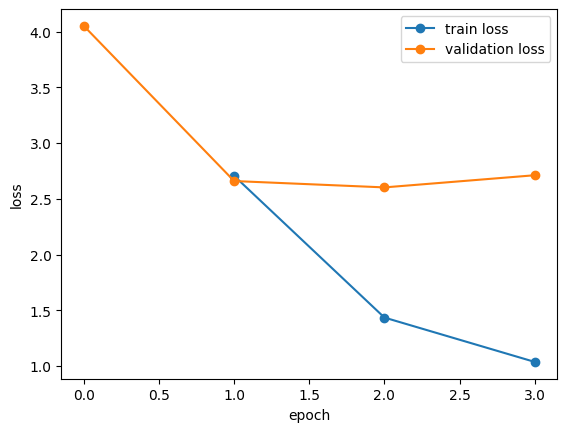

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('checkpoints/sft/final\\tokenizer_config.json',
 'checkpoints/sft/final\\tokenizer.json')

In [ ]:
log = sft_trainer.state.log_history
sft_train_loss = [(x["epoch"], x["loss"]) for x in log if "loss" in x]
sft_eval_loss = [(0, val_loss_before)] + [(x["epoch"], x["eval_loss"]) for x in log if "eval_loss" in x]
print("train loss:", [(e, round(l, 3)) for e, l in sft_train_loss])
print("val loss  :", [(e, round(l, 3)) for e, l in sft_eval_loss])

plt.plot(*zip(*sft_train_loss), marker="o", label="train loss")
plt.plot(*zip(*sft_eval_loss), marker="o", label="validation loss")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend()
plt.savefig("sft_loss_curve.png")
plt.show()

sft_trainer.save_model("checkpoints/sft/final")
sft_tokenizer.save_pretrained("checkpoints/sft/final")

In [ ]:
gen_max_new_tokens = 200

def sft_generate(model, question):
    model.eval()
    inputs = sft_tokenizer(build_prompt(question), return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(
            **inputs,
            max_new_tokens=gen_max_new_tokens,
            do_sample=False,
            eos_token_id=[END_ID, sft_tokenizer.eos_token_id],
            pad_token_id=sft_tokenizer.eos_token_id,
        )
    new_ids = out[0][inputs["input_ids"].shape[1]:].tolist()
    return sft_tokenizer.decode(new_ids, skip_special_tokens=True).strip(), (END_ID in new_ids or sft_tokenizer.eos_token_id in new_ids)

check_prompts = prompts + ["What is the capital of Japan?", "What does a Sony WH-1000XM5 cost at the moment?"]
for p in check_prompts:
    answer, stopped = sft_generate(sft_model, p)
    print("Q:", p)
    print("A:", answer)
    print("stopped at <|end|>:", stopped)
    print("---")

sft_ppl = get_perplexity(sft_model, val_dataset)
print("Base:", round(base_ppl, 2), "| CPT:", round(cpt_ppl, 2), "| SFT:", round(sft_ppl, 2))

Q: Are the products on Orange eShop authentic?
A: I focus on the provided Orange eShop FAQs and don’t have verified information to answer that question.
stopped at <|end|>: True
---
Q: How can I track my order?
A: You can track the status of your order from my orders page https://eshop.orange.jo/en/order/aramextrackyourorder
stopped at <|end|>: True
---
Q: Can I change my order after I place it?
A: You can receive your order from me as soon as you place your order. Please contact eShop support for confirmation.
stopped at <|end|>: True
---
Q: Is there a warranty on the products?
A: I focus on the provided Orange eShop FAQs and don’t have verified information to answer that question.
stopped at <|end|>: True
---
Q: How can I pay for my order?
A: You can pay with cash, cheque, money order, money order confirmation email, cashier's check, money order confirmation email, money order confirmation email, money order confirmation email, money order confirmation email, money order confirmation

In [ ]:
TEST_PATH = "data/seed_test_30.csv"
RESULTS_DIR = "results"
MAX_NEW_TOKENS = 200
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

REFUSAL_CATEGORIES = {
    "live_or_missing_information",
    "unsupported_claim_request",
    "out_of_scope",
}

REFUSAL_PHRASES = [
    "don’t have verified information",
    "don't have verified information",
    "do not have verified information",
    "cannot confirm",
    "can't confirm",
    "outside the information",
    "does not provide verified",
    "i focus on the provided orange eshop faqs",
]


def format_prompt(question: str, use_chat_template: bool) -> str:
    if use_chat_template:
        return f"<|user|>\n{question}\n<|assistant|>\n"
    return f"Question: {question}\nAnswer:"


def generate_answer(
    model: GPT2LMHeadModel,
    tokenizer: GPT2Tokenizer,
    question: str,
    use_chat_template: bool,
    max_new_tokens: int = MAX_NEW_TOKENS,
) -> tuple[str, float, bool]:
    model.eval()
    prompt = format_prompt(question, use_chat_template)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    stop_ids = [tokenizer.eos_token_id]
    if use_chat_template:
        end_id = tokenizer.convert_tokens_to_ids("<|end|>")
        if end_id is not None and end_id != tokenizer.unk_token_id:
            stop_ids.append(end_id)
    else:
        nl_ids = tokenizer.encode("\n", add_special_tokens=False)
        if nl_ids:
            stop_ids.append(nl_ids[0])

    t0 = time.perf_counter()
    with torch.no_grad():
        out = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            eos_token_id=stop_ids,
            pad_token_id=tokenizer.eos_token_id,
        )
    latency = time.perf_counter() - t0

    new_ids = out[0][inputs["input_ids"].shape[1] :].tolist()
    stopped_cleanly = any(sid in new_ids for sid in stop_ids)
    answer = tokenizer.decode(new_ids, skip_special_tokens=True).strip()
    return answer, latency, stopped_cleanly


def is_refusal(answer: str) -> bool:
    low = answer.lower()
    return any(phrase in low for phrase in REFUSAL_PHRASES)


def evaluate_model(
    version_name: str,
    model_path: str,
    use_chat_template: bool,
    test_df: pd.DataFrame,
) -> dict:
    print(f"\n=== Evaluating {version_name} ({model_path}) ===")
    tokenizer = GPT2Tokenizer.from_pretrained(model_path)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    model = GPT2LMHeadModel.from_pretrained(model_path).to(DEVICE)

    rows = []
    for _, row in test_df.iterrows():
        q = str(row["question"]).strip()
        expected = str(row["expected_answer"]).strip()
        cat = str(row["category"]).strip()
        should_refuse = cat in REFUSAL_CATEGORIES

        ans, latency, stopped = generate_answer(
            model, tokenizer, q, use_chat_template=use_chat_template
        )
        detected_refusal = is_refusal(ans)

        rows.append(
            {
                "id": row["id"],
                "category": cat,
                "should_refuse": should_refuse,
                "question": q,
                "expected_answer": expected,
                "model_answer": ans,
                "stopped_cleanly": stopped,
                "auto_detected_refusal": detected_refusal,
                "latency_s": round(latency, 4),
                "grader1_score": "",
                "grader2_score": "",
                "final_score": "",
                "error_cause": "",
                "note": "",
            }
        )

    res_df = pd.DataFrame(rows)
    out_file = os.path.join(RESULTS_DIR, f"{version_name}_results.csv")
    res_df.to_csv(out_file, index=False, encoding="utf-8-sig")

    avg_latency = res_df["latency_s"].mean()
    refusal_subset = res_df[res_df["should_refuse"]]
    auto_refusal_acc = (
        refusal_subset["auto_detected_refusal"].mean() * 100
        if len(refusal_subset) > 0
        else 0.0
    )
    print(f"Saved: {out_file}")
    print(
        f"Avg latency: {avg_latency:.3f}s | Auto-detected refusal accuracy (4 cases): {auto_refusal_acc:.1f}%"
    )
    return {
        "version": version_name,
        "avg_latency_s": round(avg_latency, 3),
        "auto_refusal_acc_pct": round(auto_refusal_acc, 1),
    }


def main():
    os.makedirs(RESULTS_DIR, exist_ok=True)
    test_df = pd.read_csv(TEST_PATH)

    models = [
        ("base", "gpt2", False),
        ("cpt", "checkpoints/cpt/final", False),
        ("sft", "checkpoints/sft/final", True),
    ]

    summary = []
    for name, path, use_chat in models:
        if name != "base" and not os.path.exists(path):
            print(f"Skipping {name}: {path} not found")
            continue
        summary.append(evaluate_model(name, path, use_chat, test_df))

    print("\n=== Summary ===")
    print(pd.DataFrame(summary).to_string(index=False))


if __name__ == "__main__":
    main()


=== Evaluating base (gpt2) ===


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Saved: results\base_results.csv
Avg latency: 0.226s | Auto-detected refusal accuracy (4 cases): 0.0%

=== Evaluating cpt (checkpoints/cpt/final) ===


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Saved: results\cpt_results.csv
Avg latency: 0.419s | Auto-detected refusal accuracy (4 cases): 0.0%

=== Evaluating sft (checkpoints/sft/final) ===


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Saved: results\sft_results.csv
Avg latency: 0.211s | Auto-detected refusal accuracy (4 cases): 100.0%

=== Summary ===
version  avg_latency_s  auto_refusal_acc_pct
   base          0.226                   0.0
    cpt          0.419                   0.0
    sft          0.211                 100.0


# **Generated LLM Questions**

faq_006: Delivery Times

What is the expected delivery time if I place my order during a weekday?
Will my purchase arrive faster if I order on a working day?
How does ordering on a weekend versus a weekday affect my delivery time?
What should I expect in terms of delivery speed when I place an order on a business day?
Do orders placed during weekday business hours get delivered sooner than weekend orders?
How is the delivery timeline determined for regions outside the major urban centers?
Can I get next-day delivery if I place my order on a Saturday?
What factors influence how quickly my order will arrive at my address?


faq_007: Shipment Tracking

Where can I monitor the current location of my package?
Is there a way to check on the progress of my delivery?
How do I access the shipment monitoring system?
What page on your website shows me where my order is?
Can I see real-time updates about my shipment somewhere?
How can I view the status updates for my purchase?
Where should I go to check if my delivery is on its way?
Is there an online tool to check my order's current status?


faq_008: Payment Methods

What are the different payment methods available on your eShop?
Do you offer cash on delivery as a payment option?
Is it possible to pay with my mobile wallet?
What digital payment options do you support?
Can I settle my bill when my order arrives at my door?
Which online payment methods does your store accept?
Are mobile wallets like Orange Money accepted for purchases?
What payment options are available besides cash on delivery?


faq_009: Promotional Codes

How do I input my discount code during checkout?
Where should I enter a promotional code when buying?
What steps do I need to follow to apply a coupon?
How can I activate my discount code on your website?
At what point in the purchase process should I use my promo code?
Is there a specific button I need to click to apply my coupon?
How do I make sure my discount code actually gets applied to my order?
What's the correct way to redeem a promotional code at checkout?


faq_010: Refund Amounts

Will I receive a complete refund if I return my device?
How is the refund amount decided for different situations?
Does my specific circumstance affect whether I get a refund?
Are refunds evaluated on an individual basis?
What determines if a full refund will be processed?
Will different customers receive different refund amounts depending on their situation?
How does your shop assess each refund request?
Is the refund amount the same for everyone or does it vary by case?


faq_011: Refund Process

Is the refund process for online orders the same as it would be in a physical store?
Does the eShop follow the same refund procedure as your regular shops?
What steps should I follow to get a refund for my online purchase?
How does returning items for a refund work at your eShop?
Are the refund procedures identical whether I shop online or at your physical location?
Does my eShop purchase follow the standard refund process you use elsewhere?
Is the refund system for the eShop consistent with your brick-and-mortar stores?
What is the refund procedure when I buy from your online platform?


faq_012: Return/Refund Conditions

Can I decline my order if I haven't yet signed the agreement?
What happens to my payment if I reject the shipment before signing?
Am I able to return my purchase after I've already signed the contract?
What is the return policy for orders where I've paid but not signed the agreement yet?
If I reject my delivery before signing any paperwork, will the courier take it back?
Is it possible to cancel my order after paying but before signing the contract?
Once I've signed the contract and completed payment, am I locked in?
What are my options if I want to decline the delivery at my door without signing?


faq_013: Contact Methods

What are the ways I can reach out to your support team?
How can I get in touch with the eShop regarding my issue?
What communication channels do you offer for customer inquiries?
Is there an email address where I can send you a message?
Can I contact you through a messaging app like WhatsApp?
What methods are available for me to communicate with your store?
How can I send a message to the eShop support?
Are there different ways I can contact you about my order?


faq_014: eShop Overview

Can I shop for Orange products without leaving my home?
Do I need to visit a store in person to purchase from Orange?
What types of items can I purchase through your online platform?
Is the eShop service available for people living in Jordan?
Can I buy mobile phones directly from your website?
What products does the Orange Jordan eShop offer for purchase?
Is it possible to get Orange service packages online without going to a branch?
Does the eShop allow me to shop for devices from anywhere in the country?


faq_015: Product Catalog Categories

What product categories are available on the eShop?
Can I buy smartwatches and wearable devices from your platform?
Does your catalog include home appliances and entertainment devices?
Are tablets and laptops sold through the eShop?
If an item appears in the catalog, does that mean it's available to purchase?
What varieties of devices can I browse and order from your website?
Just because a product is listed in your catalog, is it guaranteed to be in stock?
Do you sell network devices and smart home equipment online?


faq_016: Accessories

Do you sell phone cases and protective covers for devices?
Are power banks available for purchase on the eShop?
Where can I find mobile phone accessories on your platform?
What protective accessories do you offer for smartphones?
How do I check if a specific accessory item is currently in stock?
Are charging accessories like portable power banks sold through your eShop?
Can I browse different types of protective covers for my device?
Where should I look to see what accessories you have and their current availability?


faq_017: Smartwatches

Do you sell smartwatches on your eShop?
What types of wearable devices are listed on your website?
How can I find which smartwatch models you currently have in stock?
Are fitness and health tracking wearables available for purchase?
Where should I look to see the different smartwatch options you offer?
What wearable technology products can I browse on the platform?
How do I check the availability of specific smartwatch models?
Can I view all the different smartwatch brands and models you sell?


faq_018: Audio & Entertainment

Do you sell audio equipment like headphones and speakers?
Are gaming peripherals and accessories available for purchase on the eShop?
What home and entertainment products are included in your catalog?
Can I find speakers for music or home use on your platform?
Does your eShop offer gaming-related accessories and equipment?
What types of audio devices can I browse on your website?
Are entertainment devices part of the categories you offer?
Can I purchase headphones and similar audio gear from your store?


faq_019: Tablets & Laptops

Can I buy tablets through the eShop?
Are laptops available for purchase on your platform?
How do I find the different tablet and laptop models you offer?
Where can I check which laptops are currently available?
What tablet options does your catalog have?
Can I browse different laptop brands and specifications on your website?
How do I see the various tablet models you stock?
Is there a section where I can view laptops and tablets together?


faq_020: Network Devices

Do you sell WiFi routers?
Are network devices like signal extenders available on the eShop?
What networking equipment can I purchase from your platform?
Where should I look to find WiFi routers in your catalog?
Do you carry products to improve home WiFi coverage?
Can I browse different WiFi extender models on your website?
What types of network devices are offered in your store?
How do I check the availability of specific routing or networking equipment?


faq_021: Smart Home Devices

Do you sell security cameras for home surveillance?
Are robot vacuums available for purchase on the eShop?
What smart home products are included in your catalog?
Can I find automated cleaning devices on your platform?
Where should I look to browse smart home devices?
Do you carry security monitoring equipment for the home?
What types of smart home automation products do you offer?
How do I check if a specific smart home device is in stock?


faq_022: Home Appliances

Do you sell smart televisions through the eShop?
Are washing machines available for purchase on your platform?
Can I buy dishwashers from your online store?
What major home appliances are included in your catalog?
If an appliance appears in your product listing, does that guarantee it's available?
Where can I find refrigerators and other large household appliances?
Does the presence of a home appliance in your categories mean you have it in stock?
What types of smart TVs and kitchen appliances do you offer?


faq_023: Free Delivery

Is there a delivery charge for my order?
Do you offer free shipping to customers?
Will my purchase be delivered directly to my home?
Are there any shipping costs I need to pay?
Where will my order be delivered?
Do all orders qualify for free doorstep delivery?
Are there any special conditions that might affect my delivery?
How can I check what delivery terms apply to my specific order?


faq_024: Filtering & Sorting

How can I filter the products by category?
Is there a way to sort items by their price?
Can I search for products within a specific price range?
What options do I have for organizing the catalog when browsing?
Can I sort the product list alphabetically by name?
How do I narrow down devices by price on your eShop?
What filtering and sorting tools are available when shopping?
Can I arrange the products in different orders to find what I'm looking for?


faq_025: Promotions Page

Where can I find current promotions and special offers on the eShop?
What product categories are included in your promotional offers?
Are there active deals available on mobile line subscriptions?
How can I learn about the terms and conditions of your current promotions?
Do you have discounts on internet connectivity plans?
Where is the best place to check for the latest deals and offers?
What smart home device promotions are running at the moment?
Can I find special pricing on mobile phone accessories and gadgets?


faq_026: Contact Phone & Email

What is the phone number to call for support?
How can I reach the help center by telephone?
What email address should I use to contact the eShop team?
Can I get assistance by calling or emailing support?
Where can I find all the contact information for customer service?
What communication methods are listed in the help center?
How do I send an email to request help with my order?
What are the different ways I can reach the support team?


faq_027: Contact Form

What information do I need to provide on the Contact Us form?
Does the Contact Us page require my email address?
What details should I include when submitting an inquiry through the website?
Is there a form on the Contact Us page to send a message?
What fields need to be filled out on the contact form?
How do I submit my contact information through the eShop website?
What do I need to enter when filling out the inquiry form?
Can I find a contact form on the website to submit my request?


faq_028: Returns & Refunds Page

Where can I find detailed information about the refund policy?
How are individual refund amounts determined on a case-by-case basis?
Does the Returns and Refund page explain how refunds are processed?
Why might the refund amount vary from one customer to another?
Are refund decisions made individually for each request?
What does the Returns and Refund page say about how refunds work?
Is there a standard refund amount or does it depend on circumstances?
Where should I look to understand how my specific refund would be handled?


faq_029: Return Policy (Signed Contract)

Are returns available for purchases where both payment and contract signature have been completed?
How can I find out if my particular purchase can be returned?
Should I contact support to determine if my order is eligible for a return?
What is the return policy status for orders that have been signed and paid?
If payment has been made and a contract signed, what are my return rights?
Is it necessary to speak with customer support to confirm my return eligibility?
How do I verify whether the return restrictions apply to my specific order?
What prevents me from returning a device after signing the purchase agreement?


faq_030: Privacy Policy (Data Types)

What types of personal information does Orange collect from customers?
Does the privacy policy cover location and device information?
What payment details are included in Orange's privacy policy?
Is website and app activity tracked according to the privacy policy?
Does Orange's privacy policy apply to all their services or just eShop?
What categories of data are mentioned in the general privacy policy?
Are communications and support interactions included in the data collection?
What registration and identification information does the privacy policy describe?


faq_031: Privacy Policy (Data Use)

Why does Orange use the personal information I provide?
What purposes does my data serve according to the privacy policy?
Does Orange use customer data to enhance and improve their services?
How is personal information utilized for billing and payment processing?
Can my data be used to address complaints and customer inquiries?
Is customer information processed to comply with legal and regulatory requirements?
What happens to my data after I place an order on the eShop?
Does improving service quality involve analyzing customer personal data?


faq_032: Data Retention

How long does Orange retain my personal information?
Is there a fixed timeframe for data retention on all customer data?
Does the length of time my data is kept depend on why it was collected?
What factors influence how long Orange keeps my personal information?
Are legal or regulatory requirements part of deciding data retention periods?
Why might different types of customer data be kept for different durations?
Does Orange have a standard retention schedule for all personal data?
How does Orange determine when to delete customer information?


faq_033: Data Deletion & Erasure

Can I request to have my personal data deleted?
What circumstances allow me to ask for my information to be erased?
If I withdraw my consent, will my data be permanently removed?
Are there situations where Orange cannot delete my personal information?
What happens when my data is no longer needed for its original purpose?
Can I demand erasure of all my details if I withdraw permission?
Does the privacy policy explain when data deletion requests might be denied?
Are there legal reasons that prevent Orange from erasing customer information?


faq_034: 3MP Indoor Camera

Is there an indoor security camera available on the eShop?
Where can I find the pricing information for the indoor camera product?
What are the technical specifications of the 3MP camera?
How do I check the availability of the featured camera?
What items are currently displayed on the eShop homepage?
Can I view detailed information about the 3MP indoor camera?
How can I verify if the security camera is currently in stock?
Where should I look to find the complete specs and price of the camera?


faq_035: Fiber 800 Mbps Plan

What fiber internet plans are currently featured on the eShop?
Is the 800 Mbps fiber plan available in my coverage area?
Where can I check the pricing for the high-speed fiber internet offer?
What eligibility criteria apply to the featured connectivity plan?
Are there specific terms and conditions for the promoted fiber package?
How can I determine if my location qualifies for the fiber internet plan?
What are the details of the current fiber broadband promotion?
Can I find information about coverage and pricing for the featured internet offer?


faq_036: 5G Home Premium Offer

What is the 5G Home Premium package and what does it offer?
Is the 5G Home Premium service available in my area?
Who is eligible to subscribe to the 5G Home Premium plan?
How much does the 5G Home Premium offer cost?
What are the key terms and conditions for the 5G Home Premium service?
Where can I find detailed information about the 5G Home Premium promotion?
What coverage areas does the 5G Home Premium plan include?
Can I check if my location qualifies for the 5G Home Premium offer?